# Task-12 (Week-5)

**Date** :- (05-11-26)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Compare and evaluate different hyperparameter tuning strategies (Grid Search, Random Search, Bayesian Optimization) on model performance, training time, and scalability for deployment.

In [27]:
# Import Library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import optuna
import time

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_score
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [28]:
# Load the dataset
df = pd.read_csv("Admission_Prediction.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (1000, 18)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Year,Application_Date,University_Name,region,Admission Status,Duration_Months,Dropout_Event,Dropout-free survival,Survival_Data_Note
0,104,317,104,2,4.5,4.0,8.47,0,0.57,2022,2022-01-03,Indian Institute of Technology Bombay,West,Rejected,36,0,0.536473,SIMULATED proxy derived from admission feature...
1,170,311,99,2,2.5,3.0,7.98,0,0.65,2022,2022-01-09,Indian Institute of Technology Delhi,North,Rejected,18,1,0.973000,SIMULATED proxy derived from admission feature...
2,138,316,100,2,1.5,3.0,8.16,1,0.71,2022,2022-01-12,Indian Institute of Technology Delhi,North,Rejected,33,0,0.597989,SIMULATED proxy derived from admission feature...
3,147,315,105,3,2.0,2.5,8.48,0,0.75,2022,2022-01-13,Indian Institute of Technology Delhi,North,Accepted,33,0,0.597989,SIMULATED proxy derived from admission feature...
4,117,299,102,3,4.0,3.5,8.62,0,0.56,2022,2022-01-14,Indian Institute of Technology Delhi,North,Rejected,28,1,0.734170,SIMULATED proxy derived from admission feature...


In [29]:
# Data preprocessing

# Remove unnecessary columns
df = df.drop(
    columns=[
        "Serial No.",
        "Chance of Admit",
        "Application_Date",
        "Year",
        "Duration_Months",
        "Dropout_Event",
        "Dropout-free survival",
        "Survival_Data_Note"
    ],
    errors="ignore"
)

# Clean target values
df["Admission Status"] = (
    df["Admission Status"]
    .astype(str)
    .str.strip()
    .str.title()
)

# Keep only Accepted and Rejected
df = df[
    df["Admission Status"].isin(["Accepted", "Rejected"])
].copy()

# Separate features and target
X = df.drop("Admission Status", axis=1)

y = df["Admission Status"].map({
    "Rejected": 0,
    "Accepted": 1
})

print("Features Shape:", X.shape)
print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (1000, 9)

Target Distribution:
Admission Status
0    565
1    435
Name: count, dtype: int64


In [30]:
# Identify numerical and categorical columns

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
Categorical Features: ['University_Name', 'region']


In [31]:
# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (800, 9)
Testing Data: (200, 9)


In [32]:
# Create preprocessing and machine learning pipeline

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Complete pipeline
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [33]:
# Grid Search

# Hyperparameter grid
param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", "log2"]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Measure training time
start_time = time.perf_counter()

grid_search.fit(X_train, y_train)

grid_time = time.perf_counter() - start_time

# Results
print("Grid Search Best Parameters:")
print(grid_search.best_params_)

print("Grid Search Best CV F1 Score:")
print(grid_search.best_score_)

print("Grid Search Training Time:")
print(round(grid_time, 2), "seconds")

Grid Search Best Parameters:
{'model__max_depth': 20, 'model__max_features': 'log2', 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Grid Search Best CV F1 Score:
0.5670180132169252
Grid Search Training Time:
36.39 seconds


In [34]:
# Random Search

from scipy.stats import randint

# Hyperparameter distributions
param_dist = {
    "model__n_estimators": randint(100, 401),
    "model__max_depth": [None, 10, 15, 20, 25, 30],
    "model__min_samples_split": randint(2, 11),
    "model__min_samples_leaf": randint(1, 6),
    "model__max_features": ["sqrt", "log2"]
}

# Random Search
random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True
)

# Measure training time
start_time = time.perf_counter()

random_search.fit(X_train, y_train)

random_time = time.perf_counter() - start_time

# Results
print("Random Search Best Parameters:")
print(random_search.best_params_)

print("Random Search Best CV F1 Score:")
print(random_search.best_score_)

print("Random Search Training Time:")
print(round(random_time, 2), "seconds")

Random Search Best Parameters:
{'model__max_depth': 25, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 188}
Random Search Best CV F1 Score:
0.5523292672807236
Random Search Training Time:
15.92 seconds


In [35]:
# Bayesian Optimization using Optuna

# Define objective function
def objective(trial):

    params = {
        "model__n_estimators": trial.suggest_int(
            "n_estimators", 100, 400
        ),

        "model__max_depth": trial.suggest_categorical(
            "max_depth", [None, 10, 15, 20, 25, 30]
        ),

        "model__min_samples_split": trial.suggest_int(
            "min_samples_split", 2, 10
        ),

        "model__min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 1, 5
        ),

        "model__max_features": trial.suggest_categorical(
            "max_features", ["sqrt", "log2"]
        )
    }

    model = pipeline.set_params(**params)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    return scores.mean()

In [36]:
# run the Optuna study

# Create Bayesian optimization study
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

# Measure total time
start_time = time.perf_counter()

# Run 30 trials
study.optimize(objective, n_trials=30)

# Create best model
best_bayesian_model = pipeline.set_params(
    **{
        f"model__{key}": value
        for key, value in study.best_params.items()
    }
)

# Train best model
best_bayesian_model.fit(X_train, y_train)

bayesian_time = time.perf_counter() - start_time

# Results
print("Bayesian Optimization Best Parameters:")
print(study.best_params)

print("Bayesian Optimization Best CV F1 Score:")
print(study.best_value)

print("Bayesian Optimization Training Time:")
print(round(bayesian_time, 2), "seconds")

[I 2026-11-08 10:32:22,113] A new study created in memory with name: no-name-5d1ff792-455e-4887-8321-bd3be89c22f1
[I 2026-11-08 10:32:22,939] Trial 0 finished with value: 0.5543588387280532 and parameters: {'n_estimators': 212, 'max_depth': None, 'min_samples_split': 9, 'min_samples_leaf': 4, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.5543588387280532.
[I 2026-11-08 10:32:24,047] Trial 1 finished with value: 0.5497206562315566 and parameters: {'n_estimators': 391, 'max_depth': None, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.5543588387280532.
[I 2026-11-08 10:32:24,585] Trial 2 finished with value: 0.5440178913126674 and parameters: {'n_estimators': 187, 'max_depth': 15, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.5543588387280532.
[I 2026-11-08 10:32:25,796] Trial 3 finished with value: 0.5447845804988662 and parameters: {'n_estimators': 385, 'max_depth': No

Bayesian Optimization Best Parameters:
{'n_estimators': 212, 'max_depth': None, 'min_samples_split': 9, 'min_samples_leaf': 4, 'max_features': 'sqrt'}
Bayesian Optimization Best CV F1 Score:
0.5543588387280532
Bayesian Optimization Training Time:
20.76 seconds


In [37]:
# Evaluate all 3 models

# Store the best models
models = {
    "Grid Search": grid_search.best_estimator_,
    "Random Search": random_search.best_estimator_,
    "Bayesian Optimization": best_bayesian_model
}

results = []

for name, model in models.items():

    # Predictions
    y_pred = model.predict(X_test)

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "Tuning Strategy": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

performance_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(performance_df.round(4))

Model Performance Comparison:


,Tuning Strategy,Accuracy,Precision,Recall,F1 Score
0,Grid Search,0.665,0.6613,0.4713,0.5503
1,Random Search,0.655,0.6500,0.4483,0.5306
2,Bayesian Optimization,0.670,0.6842,0.4483,0.5417


In [38]:
# Compare training time

time_df = pd.DataFrame({
    "Tuning Strategy": [
        "Grid Search",
        "Random Search",
        "Bayesian Optimization"
    ],

    "Training Time (Seconds)": [
        grid_time,
        random_time,
        bayesian_time
    ]
})

display(time_df.round(2))

,Tuning Strategy,Training Time (Seconds)
0,Grid Search,36.39
1,Random Search,15.92
2,Bayesian Optimization,20.76


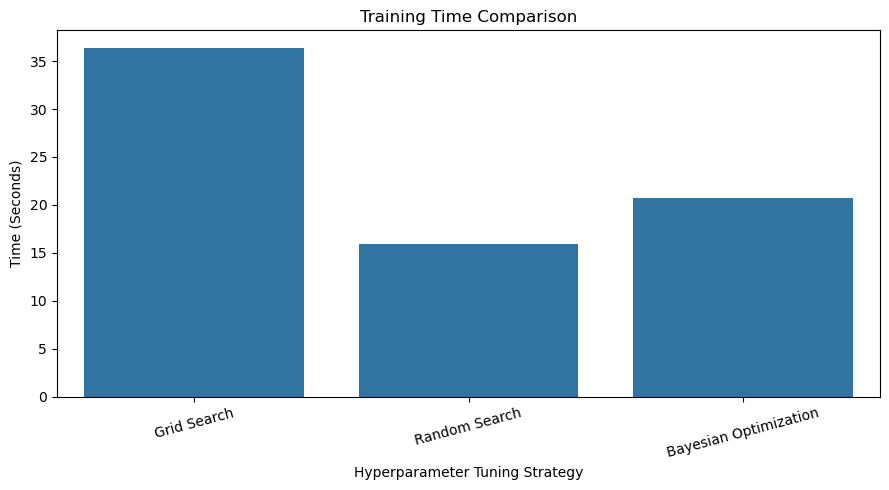

In [39]:
# Visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=time_df,
    x="Tuning Strategy",
    y="Training Time (Seconds)"
)

plt.title("Training Time Comparison")
plt.xlabel("Hyperparameter Tuning Strategy")
plt.ylabel("Time (Seconds)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [40]:
# Evaluate scalability for deployment

latency_results = []

for name, model in models.items():

    start_time = time.perf_counter()

    # Repeat prediction to get a more stable measurement
    for _ in range(50):
        model.predict(X_test)

    total_time = time.perf_counter() - start_time

    latency_ms = (
        total_time / (50 * len(X_test))
    ) * 1000

    latency_results.append({
        "Tuning Strategy": name,
        "Prediction Time (ms/applicant)": latency_ms
    })

latency_df = pd.DataFrame(latency_results)

display(latency_df.round(4))

,Tuning Strategy,Prediction Time (ms/applicant)
0,Grid Search,0.1709
1,Random Search,0.2330
2,Bayesian Optimization,0.2187


In [41]:
# create the final comparison table

final_comparison = performance_df.merge(
    time_df,
    on="Tuning Strategy"
).merge(
    latency_df,
    on="Tuning Strategy"
)

final_comparison = final_comparison.sort_values(
    by="F1 Score",
    ascending=False
)

display(final_comparison.round(4))

,Tuning Strategy,Accuracy,Precision,Recall,F1 Score,Training Time (Seconds),Prediction Time (ms/applicant)
0,Grid Search,0.665,0.6613,0.4713,0.5503,36.3938,0.1709
2,Bayesian Optimization,0.670,0.6842,0.4483,0.5417,20.7550,0.2187
1,Random Search,0.655,0.6500,0.4483,0.5306,15.9164,0.2330


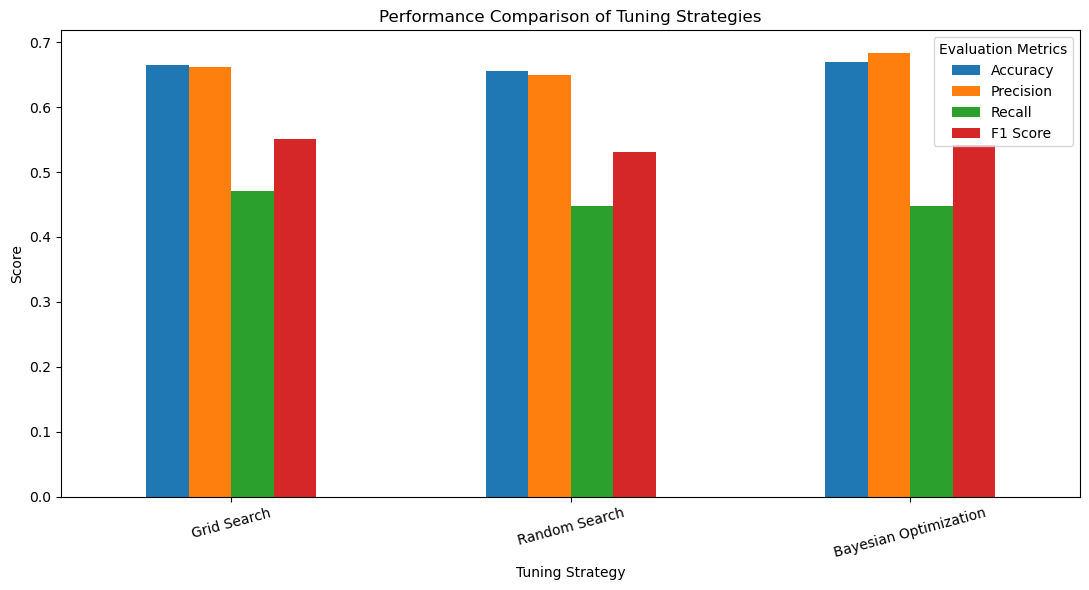

In [42]:
# visualize model performance comparison

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

performance_df.set_index(
    "Tuning Strategy"
)[metrics].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Tuning Strategies")
plt.ylabel("Score")
plt.xlabel("Tuning Strategy")
plt.xticks(rotation=15)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

In [43]:
# Identify the best tuning strategy

best_strategy = final_comparison.iloc[0]

print("Best Tuning Strategy:", best_strategy["Tuning Strategy"])

print("Accuracy:", round(best_strategy["Accuracy"], 4))

print("Precision:", round(best_strategy["Precision"], 4))

print("Recall:", round(best_strategy["Recall"], 4))

print("F1 Score:", round(best_strategy["F1 Score"], 4))

print(
    "Training Time:",
    round(best_strategy["Training Time (Seconds)"], 2),
    "seconds"
)

print(
    "Prediction Time:",
    round(best_strategy["Prediction Time (ms/applicant)"], 4),
    "ms/applicant"
)

Best Tuning Strategy: Grid Search
Accuracy: 0.665
Precision: 0.6613
Recall: 0.4713
F1 Score: 0.5503
Training Time: 36.39 seconds
Prediction Time: 0.1709 ms/applicant
